## **Assignment Simple machine Learning Project cycle**

### **_House Price Prediction Using California Housing Data_**
This dataset provides information about house prices in California. House Price Prediction

**In this notebook, you'll follow the basic machine learning process to build a regression model to predict house prices using the "California Housing Dataset" from sklearn.**

---

### **Follow the instructions and complete each TODO to complete the assessment on the essential steps in building and evaluating a regression model.**

The following is a description of each column in the dataset:

Dataset Features (California Housing):
- MedInc: Median income in block group
- HouseAge: Median house age in block group
- AveRooms: Average number of rooms per household
- AveBedrms: Average number of bedrooms per household
- Population: Block group population
- AveOccup: Average number of household members
- Latitude: Block group latitude
- Longitude: Block group longitude
- MedHouseVal (Target): Median house value in block group

## 1. Imports

In [1]:
# --- Imports ---
# Libraries for data handling, visualization and model building
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.datasets import fetch_california_housing
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, r2_score

pd.set_option('display.width', 120)
pd.set_option('display.max_columns', 20)

## 2. Data Collection and Loading

In [2]:
# --- Data Collection and Loading ---
# Load the California Housing dataset and convert it into a pandas DataFrame
housing = fetch_california_housing(as_frame=True)
df = housing.frame          # 8 features + the target column 'MedHouseVal'

print("Shape (rows, columns):", df.shape)

Shape (rows, columns): (20640, 9)


## 3. Quick Check of Data

In [3]:
# --- Quick Check of Data ---
# First rows of the dataset
print(df.head())

   MedInc  HouseAge  AveRooms  AveBedrms  Population  AveOccup  Latitude  Longitude  MedHouseVal
0  8.3252      41.0  6.984127   1.023810       322.0  2.555556     37.88    -122.23        4.526
1  8.3014      21.0  6.238137   0.971880      2401.0  2.109842     37.86    -122.22        3.585
2  7.2574      52.0  8.288136   1.073446       496.0  2.802260     37.85    -122.24        3.521
3  5.6431      52.0  5.817352   1.073059       558.0  2.547945     37.85    -122.25        3.413
4  3.8462      52.0  6.281853   1.081081       565.0  2.181467     37.85    -122.25        3.422


In [4]:
# Data types and statistics of the features and the target
df.info()
print()
print(df.describe().round(2))

# All columns are numeric (float64), so every variable is continuous
target = 'MedHouseVal'
features = [col for col in df.columns if col != target]
print("\nFeatures (continuous):", features)
print("Target (continuous):", target)
print("Categorical columns:", df.select_dtypes(exclude='number').columns.tolist())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 20640 entries, 0 to 20639
Data columns (total 9 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   MedInc       20640 non-null  float64
 1   HouseAge     20640 non-null  float64
 2   AveRooms     20640 non-null  float64
 3   AveBedrms    20640 non-null  float64
 4   Population   20640 non-null  float64
 5   AveOccup     20640 non-null  float64
 6   Latitude     20640 non-null  float64
 7   Longitude    20640 non-null  float64
 8   MedHouseVal  20640 non-null  float64
dtypes: float64(9)
memory usage: 1.4 MB

         MedInc  HouseAge  AveRooms  AveBedrms  Population  AveOccup  Latitude  Longitude  MedHouseVal
count  20640.00  20640.00  20640.00   20640.00    20640.00  20640.00  20640.00   20640.00     20640.00
mean       3.87     28.64      5.43       1.10     1425.48      3.07     35.63    -119.57         2.07
std        1.90     12.59      2.47       0.47     1132.46     10.39      2.14  

**Notes:** 20,640 block groups and 9 columns. All columns are numeric (float64), so all variables are **continuous** and there are no categorical columns. The target `MedHouseVal` is in $100,000 and is capped at 5.0.

## 4. EDA and Data Preprocessing

In [5]:
# --- EDA and Data Preprocessing ---
# Check for missing/null values
print("Missing values per column:")
print(df.isnull().sum())
print("\nTotal missing values:", df.isnull().sum().sum())

Missing values per column:
MedInc         0
HouseAge       0
AveRooms       0
AveBedrms      0
Population     0
AveOccup       0
Latitude       0
Longitude      0
MedHouseVal    0
dtype: int64

Total missing values: 0


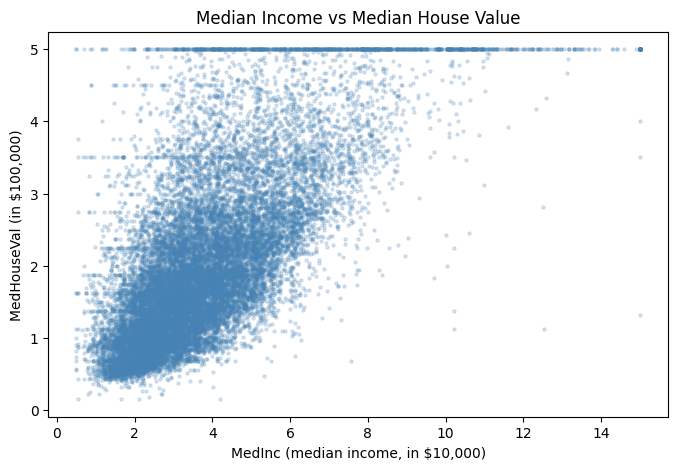

In [6]:
# Scatter plot of one feature against the target: median income vs median house value
plt.figure(figsize=(8, 5))
plt.scatter(df['MedInc'], df['MedHouseVal'], alpha=0.2, s=5, color='steelblue')
plt.title('Median Income vs Median House Value')
plt.xlabel('MedInc (median income, in $10,000)')
plt.ylabel('MedHouseVal (in $100,000)')
plt.show()

In [7]:
# Function to automate scatter plots of several features vs the target
def plot_features_vs_target(data, feature_list, target='MedHouseVal'):
    # One small plot per feature, 2 plots per row
    n_rows = (len(feature_list) + 1) // 2
    fig, axes = plt.subplots(n_rows, 2, figsize=(12, 4.5 * n_rows))
    axes = axes.flatten()
    for i, feature in enumerate(feature_list):
        if feature not in data.columns:
            print(f"'{feature}' is not a column of the DataFrame, skipped.")
            continue
        axes[i].scatter(data[feature], data[target], alpha=0.2, s=5, color='darkorange')
        # A few extreme values squash the plot, so we show up to the 99th percentile
        axes[i].set_xlim(data[feature].min(), data[feature].quantile(0.99))
        axes[i].set_title(f'{feature} vs {target}')
        axes[i].set_xlabel(feature)
        axes[i].set_ylabel(target)
    # Remove empty subplots if the number of features is odd
    for j in range(len(feature_list), len(axes)):
        fig.delaxes(axes[j])
    plt.tight_layout()
    plt.show()

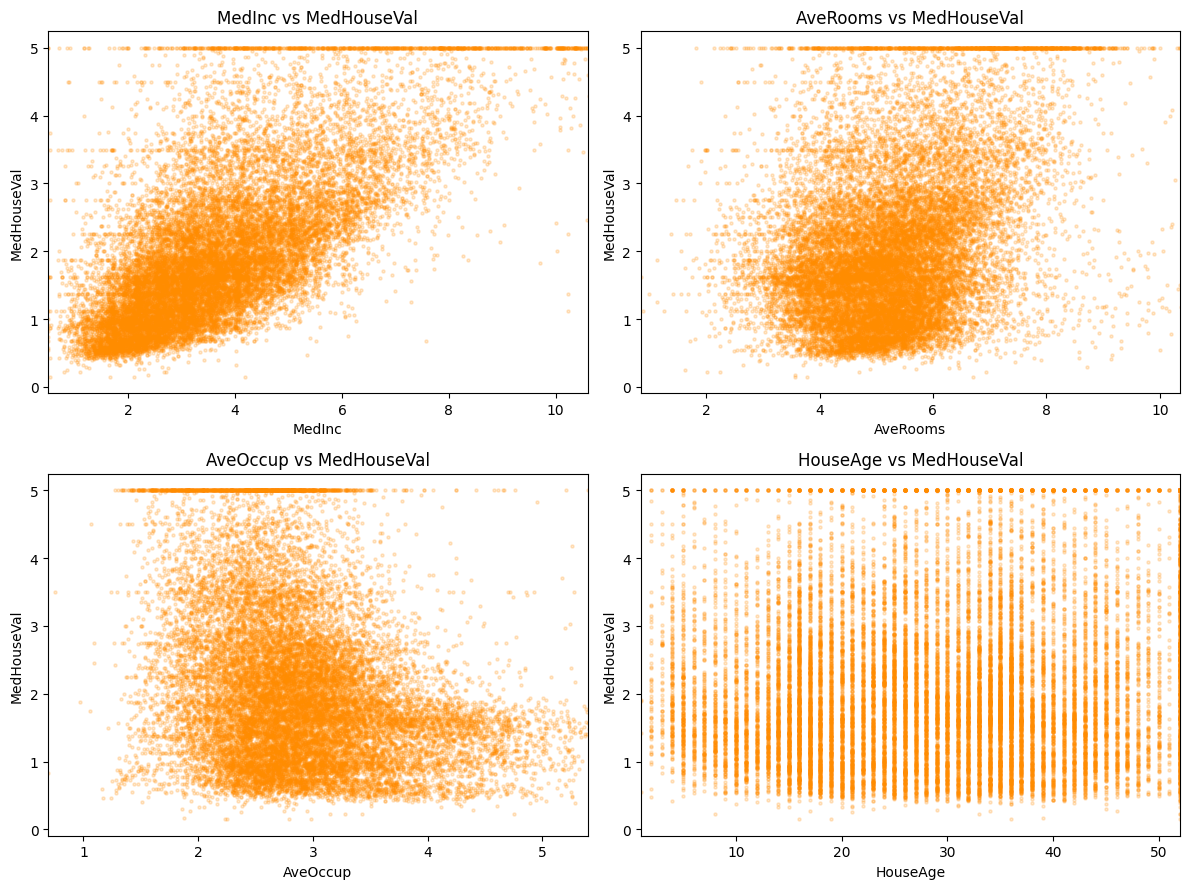

MedInc        0.688
AveRooms      0.152
HouseAge      0.106
AveOccup     -0.024
Population   -0.025
Longitude    -0.046
AveBedrms    -0.047
Latitude     -0.144
Name: MedHouseVal, dtype: float64


In [8]:
# Use the function on several features
plot_features_vs_target(df, ['MedInc', 'AveRooms', 'AveOccup', 'HouseAge'])

# Correlation of each feature with the target
print(df.corr()['MedHouseVal'].drop('MedHouseVal').sort_values(ascending=False).round(3))

**Notes:** There are no missing values. `MedInc` has the strongest link with house value (correlation 0.69): richer areas have more expensive houses. `AveRooms` (0.15) and `HouseAge` (0.11) have weak links and `AveOccup` almost none (-0.02). The flat line at 5.0 shows the capped values.

## 5. ML Model Training

In [9]:
# --- ML Model Training ---
# Features (X) and target (y), then an 80/20 train-test split
X = df.drop(columns=['MedHouseVal'])
y = df['MedHouseVal']

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
print("Training set:", X_train.shape, "| Test set:", X_test.shape)

Training set: (16512, 8) | Test set: (4128, 8)


In [10]:
# Regression model: Linear Regression
model = LinearRegression()

# Train the model on the training data
model.fit(X_train, y_train)

# Coefficients learned for each feature
print(pd.Series(model.coef_, index=X.columns).round(4))
print("Intercept:", round(model.intercept_, 4))

MedInc        0.4487
HouseAge      0.0097
AveRooms     -0.1233
AveBedrms     0.7831
Population   -0.0000
AveOccup     -0.0035
Latitude     -0.4198
Longitude    -0.4337
dtype: float64
Intercept: -37.0233


## 6. Model Evaluation

RMSE: 0.7456  (about $74,558)
R-squared: 0.5758


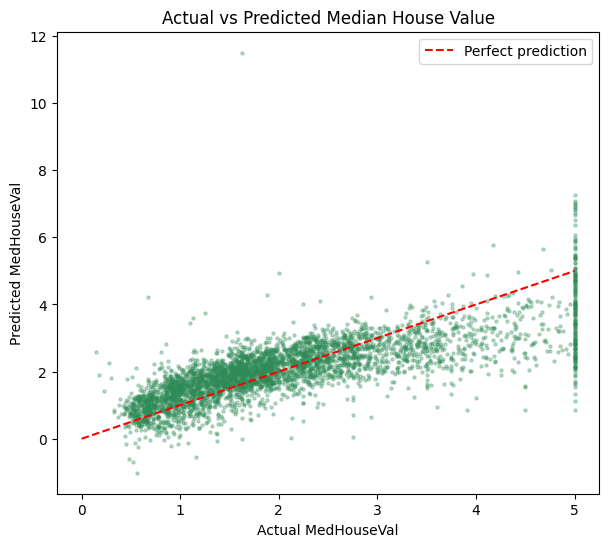

In [11]:
# --- Model Evaluation ---
# Predict on the test set and calculate RMSE and R-squared
y_pred = model.predict(X_test)

rmse = np.sqrt(mean_squared_error(y_test, y_pred))
r2 = r2_score(y_test, y_pred)
print(f"RMSE: {rmse:.4f}  (about ${rmse * 100000:,.0f})")
print(f"R-squared: {r2:.4f}")

# Predicted vs actual values
plt.figure(figsize=(7, 6))
plt.scatter(y_test, y_pred, alpha=0.3, s=5, color='seagreen')
plt.plot([0, 5], [0, 5], color='red', linestyle='--', label='Perfect prediction')
plt.title('Actual vs Predicted Median House Value')
plt.xlabel('Actual MedHouseVal')
plt.ylabel('Predicted MedHouseVal')
plt.legend()
plt.show()

**Notes:** RMSE = 0.75 (about $74,600) and R² = 0.58, so the model explains about 58% of the variation in house prices. The training R² (0.61) is close, so there is no overfitting. The model is less accurate for expensive houses because of the cap at 5.0.

## 7. Model Prediction

In [12]:
# --- Model Prediction ---
# New set of feature inputs (same column order as X)
new_house = pd.DataFrame([{
    'MedInc': 3, 'HouseAge': 30, 'AveRooms': 6, 'AveBedrms': 1,
    'Population': 1500, 'AveOccup': 3, 'Latitude': 34, 'Longitude': -118
}])[X.columns]

predicted_value = model.predict(new_house)[0]
print(new_house)
print(f"\nPredicted MedHouseVal: {predicted_value:.4f}  (about ${predicted_value * 100000:,.0f})")

   MedInc  HouseAge  AveRooms  AveBedrms  Population  AveOccup  Latitude  Longitude
0       3        30         6          1        1500         3        34       -118

Predicted MedHouseVal: 1.5487  (about $154,866)


**Notes:** For the new house, the model predicts a median value of about 1.55, or about $155,000.

## Conclusion
I followed the full machine learning cycle: loading the data, checking it, exploring it with plots, splitting it 80/20, training a Linear Regression model, evaluating it (RMSE 0.75, R² 0.58) and making a prediction. Income is the best predictor of house value. A non-linear model such as a Random Forest could improve the results.